# 55 · Teleoperation: keyboard teleop in MuJoCo, and a simulated "human" operator for headless data

In [1]:
import os, time, numpy as np, matplotlib.pyplot as plt
from vlacourse import TableTop, ScriptedExpert, collect, list_episodes, load_episode, show_images

HEADLESS = os.environ.get("VLA_HEADLESS") == "1"
KEYS = {"W": (0, 0.02), "S": (0, -0.02), "A": (1, 0.02), "D": (1, -0.02), "R": (2, 0.02), "F": (2, -0.02), "Q": (5, 0.15), "E": (5, -0.15)}

class KeyboardTeleop:
    """W/S: ±x, A/D: ±y, R/F: up/down, Q/E: yaw, SPACE: toggle gripper, ENTER: save episode, BACKSPACE: discard."""
    def __init__(self):
        self.action, self.grip, self.command = np.zeros(7), 0.0, None
    def on_key(self, keycode):
        ch = chr(keycode) if 32 <= keycode < 127 else ""
        if ch in KEYS:
            i, v = KEYS[ch]; self.action[i] += v
        elif keycode == 32:
            self.grip = 1.0 - self.grip
        elif keycode == 257:
            self.command = "save"
        elif keycode == 259:
            self.command = "discard"
    def pop(self):
        a = self.action.copy(); a[6] = self.grip; self.action[:] = 0
        return a

class SimulatedOperator:
    """The scripted expert seen through a human: reaction lag, correlated hand tremor, hesitations,
    and a personal approach style (come in from the left or from the right of the object)."""
    def __init__(self, env, rng):
        self.env, self.rng = env, rng
        self.expert = ScriptedExpert(env, seed=int(rng.integers(1 << 30)), speed=rng.uniform(0.4, 0.8), hover=rng.uniform(0.06, 0.16), tol=8e-3)   # tremor never settles within 1 mm
        side = rng.choice([-1, 1]) * rng.uniform(0.03, 0.06)
        p = self.expert.waypoints[0]
        self.expert.waypoints.insert(0, (p[0] + np.array([0, side, 0.05]), p[1], 0.0, 0))
        self.lag, self.noise, self.queue = int(rng.integers(0, 3)), np.zeros(3), []
    def act(self, obs):
        a = self.expert.act(obs)
        self.noise = 0.8 * self.noise + self.rng.normal(0, 0.003, 3)
        a[:3] += self.noise
        if self.rng.random() < 0.05:
            a[:6] = 0
        self.queue.append(a)
        return self.queue.pop(0) if len(self.queue) > self.lag else np.r_[np.zeros(6), a[6]]

In [2]:
if not HEADLESS:
    import mujoco.viewer
    env = TableTop(cameras=(), seed=0)
    tele, episodes, current = KeyboardTeleop(), [], []
    env.reset(seed=0); print("instruction:", env.task["instruction"])
    with mujoco.viewer.launch_passive(env.model, env.data, key_callback=tele.on_key) as v:
        while v.is_running() and len(episodes) < 3:
            a = tele.pop(); current.append((env.state(), a))
            with v.lock():
                env.step(a)
            v.sync(); time.sleep(0.1)
            if tele.command:
                if tele.command == "save":
                    episodes.append(current)
                current, tele.command = [], None
                env.reset(seed=len(episodes)); print("next instruction:", env.task["instruction"])
    print("recorded", len(episodes), "teleop episodes")
else:
    print("headless run: skipping the keyboard teleop session")

headless run: skipping the keyboard teleop session


In [3]:
HUMAN = os.path.abspath("../data/tabletop_human_sim_v1")
if not os.path.exists(os.path.join(HUMAN, "meta.json")):
    collect(HUMAN, n_episodes=100, seed=7, demonstrator=lambda env, rng, k: SimulatedOperator(env, rng))
human = [load_episode(p) for p in list_episodes(HUMAN)]
script = [load_episode(p) for p in list_episodes(os.path.abspath("../data/tabletop_panda_v1"))[:100]]
print(f"simulated-human episodes: {len(human)}")

  saved 25/100  (attempts 73, 85s)


  saved 50/100  (attempts 138, 156s)


  saved 75/100  (attempts 205, 232s)


  saved 100/100  (attempts 276, 313s)


simulated-human episodes: 100


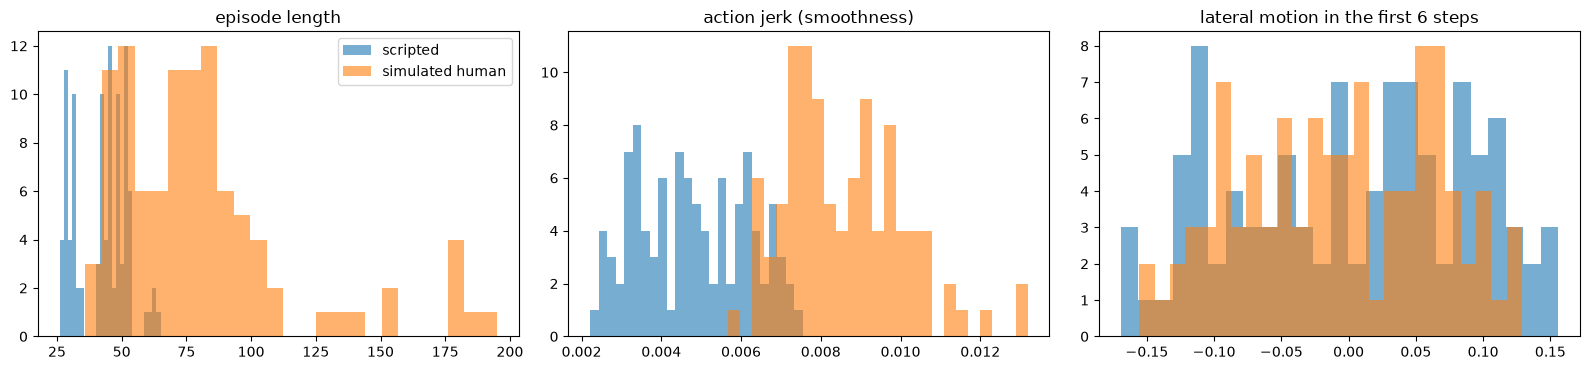

In [4]:
def jerk(ep):
    return np.abs(np.diff(ep["action"][:, :3], n=2, axis=0)).mean()

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist([len(e["action"]) for e in script], 25, alpha=0.6, label="scripted"); ax[0].hist([len(e["action"]) for e in human], 25, alpha=0.6, label="simulated human")
ax[0].set_title("episode length"); ax[0].legend()
ax[1].hist([jerk(e) for e in script], 25, alpha=0.6); ax[1].hist([jerk(e) for e in human], 25, alpha=0.6); ax[1].set_title("action jerk (smoothness)")
dy_s = [e["action"][:6, 1].sum() for e in script]; dy_h = [e["action"][:6, 1].sum() for e in human]
ax[2].hist(dy_s, 25, alpha=0.6); ax[2].hist(dy_h, 25, alpha=0.6); ax[2].set_title("lateral motion in the first 6 steps")
plt.tight_layout(); plt.show()

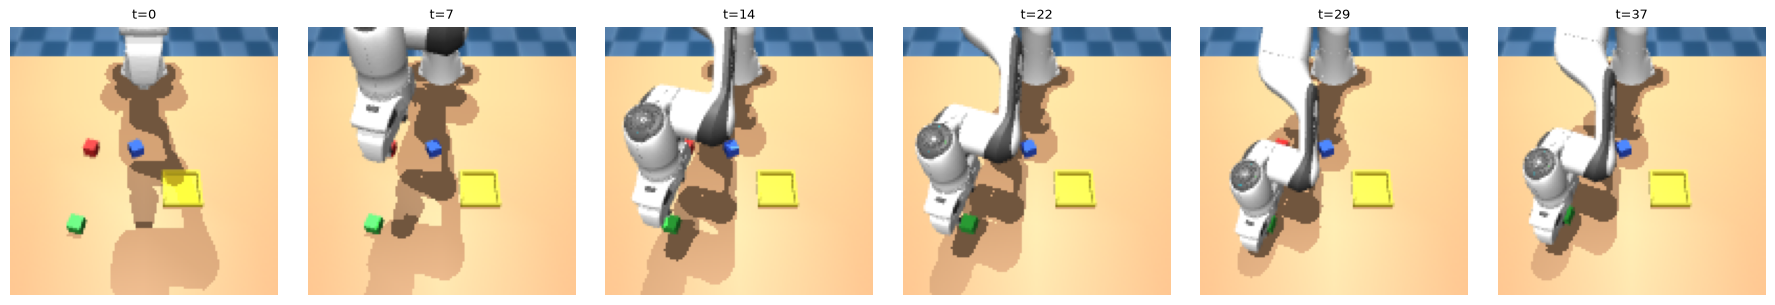

pick up the green cube


In [5]:
e = human[0]
show_images([e["front"][i] for i in np.linspace(0, len(e["action"]) - 1, 6).astype(int)], [f"t={i}" for i in np.linspace(0, len(e["action"]) - 1, 6).astype(int)], cols=6)
print(e["instruction"])